R² Score on Testing Data: 0.9753
Mean Absolute Error: 8.9730
Root Mean Squared Error: 11.8271


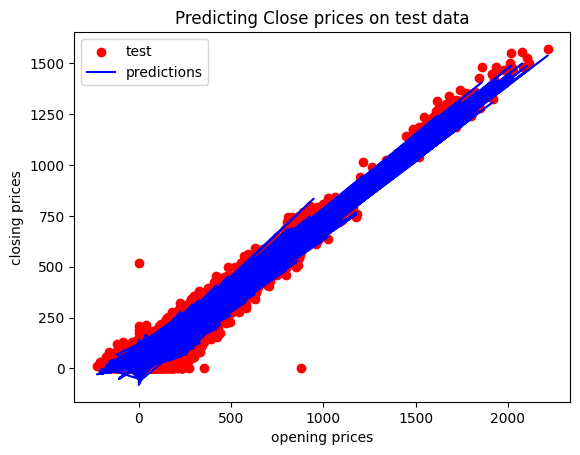

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train = train.dropna()
test = test.dropna()

X_train = train[['technical_score',
       'risk_premium','oscillator_value', 'open',
       'market_sentiment','volatility_factor'
       ]].values
y_train = train['close'].values
X_test = test[['technical_score',
       'risk_premium',  'oscillator_value', 'open',
       'market_sentiment', 'volatility_factor'

       ]].values
y_test = test['close'].values

#Add bias column (for intercept)
X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

#Compute weights using matrix method
# w = (X^T X+lamda*I)^(-1) X^T y
lambda_reg=1#for preventing overfitting using ridge regreszion
I=np.eye(X_test.shape[1])#Identity matrix
I[0,0]=0
w = np.linalg.inv(X_train.T.dot(X_train)+lambda_reg*I).dot(X_train.T).dot(y_train)


y_pred_train = X_train.dot(w)
y_pred_test=X_test.dot(w)

#Compute accuracy metrics manually
ss_res = np.sum((y_test - y_pred_test)**2)
ss_tot = np.sum((y_test - np.mean(y_test))**2)
r2_score = 1 - (ss_res / ss_tot)

mae = np.mean(np.abs(y_test - y_pred_test))
rmse = np.sqrt(np.mean((y_test - y_pred_test)**2))

print(f"R² Score on Testing Data: {r2_score:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")

predicted_close = X_test.dot(w)
test['Predicted_Close'] = predicted_close
plt.title('Predicting Close prices on test data')
plt.xlabel('opening prices')
plt.ylabel('closing prices')
plt.scatter(test['open'], test['close'],label='test',color='red')
plt.plot(test['open'], test['Predicted_Close'],label='predictions',color='blue')
plt.legend()
plt.show()
